### **Imports**

In [ ]:
%load_ext autoreload
%autoreload 2
%cd ..

import warnings
warnings.filterwarnings("ignore")

import os
import random
import torch
import numpy as np
from pathlib import Path
from huggingface_hub import hf_hub_download

from src.config import REPO_ID, HF_TOKEN
from src.processing.statistics import (
    load_and_verify_embeddings, run_theta_analysis,
    collect_surviving_frames, filter_active_embeddings, 
    group_filtered_by_video_regex, compute_inter_video_distances,
    
)
from src.utils.visualization import plot_post_kcenter_theta2_dashboard

### **Theta Analysis**

#### **Positives** 

In [15]:
embeddings_pos = load_and_verify_embeddings(
    repo_id=REPO_ID, 
    filename="embeddings/train_positives_embeddings.pt", 
    token=HF_TOKEN
)


1. Downloading embeddings from Hugging Face...

2. Loading embeddings file into memory...

3. Analysis:
  - Total frames parsed: 35228
  - Key format example: 'cross_rgb_complex_006_f0001.jpg'
  - Vector shape: (1536,)
  - L2 Norm of vector: 1.000000 (Should be ~1.0 if normalized)
  - Contains NaN: False
  - Contains Inf: False


  423 unique videos found
  Average number of frames per video: 83.3

Intra-video (theta1) statistics:
  Min: 0.0011  Max: 0.9973  Mean: 0.2827

Inter-video (theta2) statistics:
  Min: 0.0148  Max: 1.0799  Mean: 0.6472


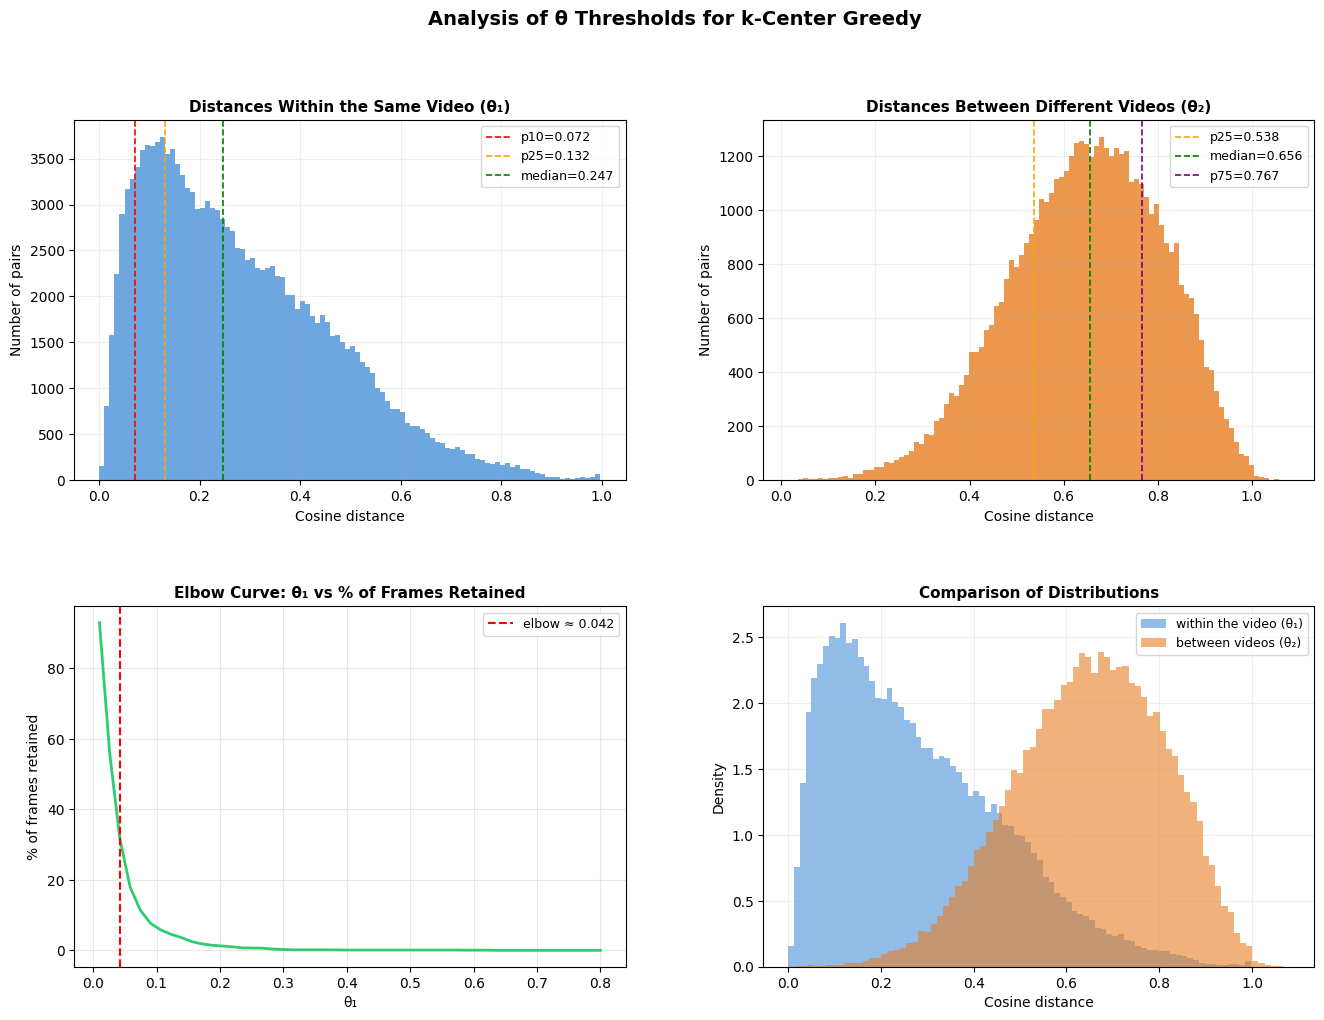


RECOMMENDATIONS FOR THETA
theta1 (video-level threshold):
  Conservative (p10):   0.0721  — removes ~10% of the most static pairs
  Elbow curve:          0.0422  — optimal balance of dataset size & diversity
  Moderate     (p25):   0.1323  — more aggressive frame removal

theta2 (dataset-level threshold):
  Conservative (p15):   0.4745  — removes redundant duplicate scenes
  Moderate     (p30):   0.5645  — more aggressive dataset pruning

Recommendation: start with theta1=0.042 and theta2=0.474
                after running Greedy selection, visually verify results on 2-3 videos


In [16]:
run_theta_analysis(embeddings_pos)

Found 8,177 frames
Filtered embeddings: 8,177 active vectors (down from 35,228)
Grouped into 423 unique videos
Frames per video — Mean: 19.3, Min: 2, Max: 103

Computing 50,000 inter-video pairwise distances...


Sampling inter-video pairs: 100%|██████████| 50000/50000 [00:01<00:00, 47982.37it/s]


Min: 0.0538  Max: 1.1127  Mean: 0.6965  Median: 0.7047


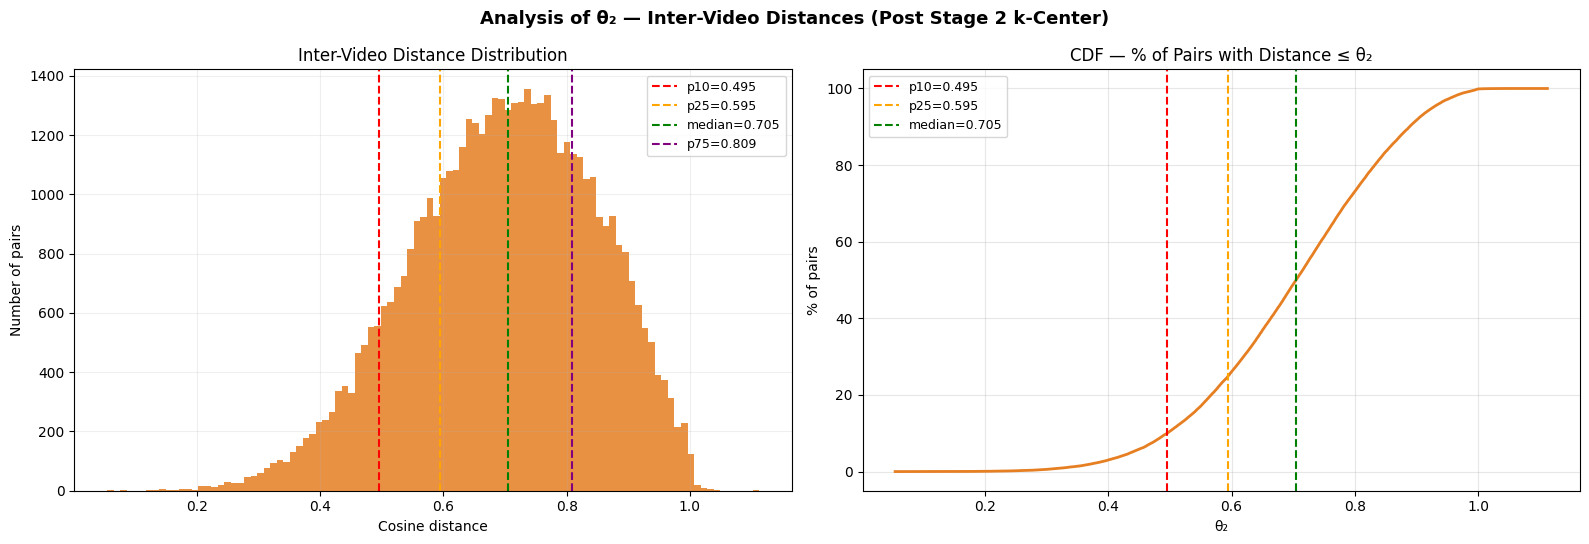


RECOMMENDATIONS FOR θ₂
  p10 = 0.4953  — Highly conservative (removes only identical background setups)
  p25 = 0.5946  — Moderate (excellent target starting point)
  median = 0.7047  — Aggressive (keeps only extremely distinct scenes)

If the left tail of your histogram starts above 0.35 - 0.40:
  -> Your videos are already highly distinct.
  -> Stage 3 global deduplication is likely NOT necessary.


In [17]:
from src.config import EXTRACTED_DATA_DIR
from src.processing.statistics import (
    collect_surviving_frames, filter_active_embeddings, 
    group_filtered_by_video_regex, compute_inter_video_distances
)
from src.utils.visualization import plot_post_kcenter_theta2_dashboard

FILTERED_DATA_DIR = EXTRACTED_DATA_DIR / "train" / "RAW_POSITIVES"
SAMPLE_PAIRS = 50_000

if not FILTERED_DATA_DIR.exists():
    print(f"Error: Checked path does not exist: {FILTERED_DATA_DIR}")
else:
    surviving_names = collect_surviving_frames(FILTERED_DATA_DIR)
    filtered_embs = filter_active_embeddings(embeddings_pos, surviving_names)
    groups_filtered = group_filtered_by_video_regex(filtered_embs)
    dists_post = compute_inter_video_distances(groups_filtered, sample_n=SAMPLE_PAIRS)
    plot_post_kcenter_theta2_dashboard(dists_post)

#### **Negatives** 

In [18]:
embeddings_neg = load_and_verify_embeddings(
    repo_id=REPO_ID, 
    filename="embeddings/train_negatives_embeddings.pt", 
    token=HF_TOKEN
)


1. Downloading embeddings from Hugging Face...

2. Loading embeddings file into memory...

3. Analysis:
  - Total frames parsed: 5938
  - Key format example: 'cross_rgb_horizon_009_f0038.jpg'
  - Vector shape: (1536,)
  - L2 Norm of vector: 1.000000 (Should be ~1.0 if normalized)
  - Contains NaN: False
  - Contains Inf: False


  69 unique videos found
  Average number of frames per video: 86.1

Intra-video (theta1) statistics:
  Min: 0.0000  Max: 0.7274  Mean: 0.0234

Inter-video (theta2) statistics:
  Min: 0.0000  Max: 0.9835  Mean: 0.4610


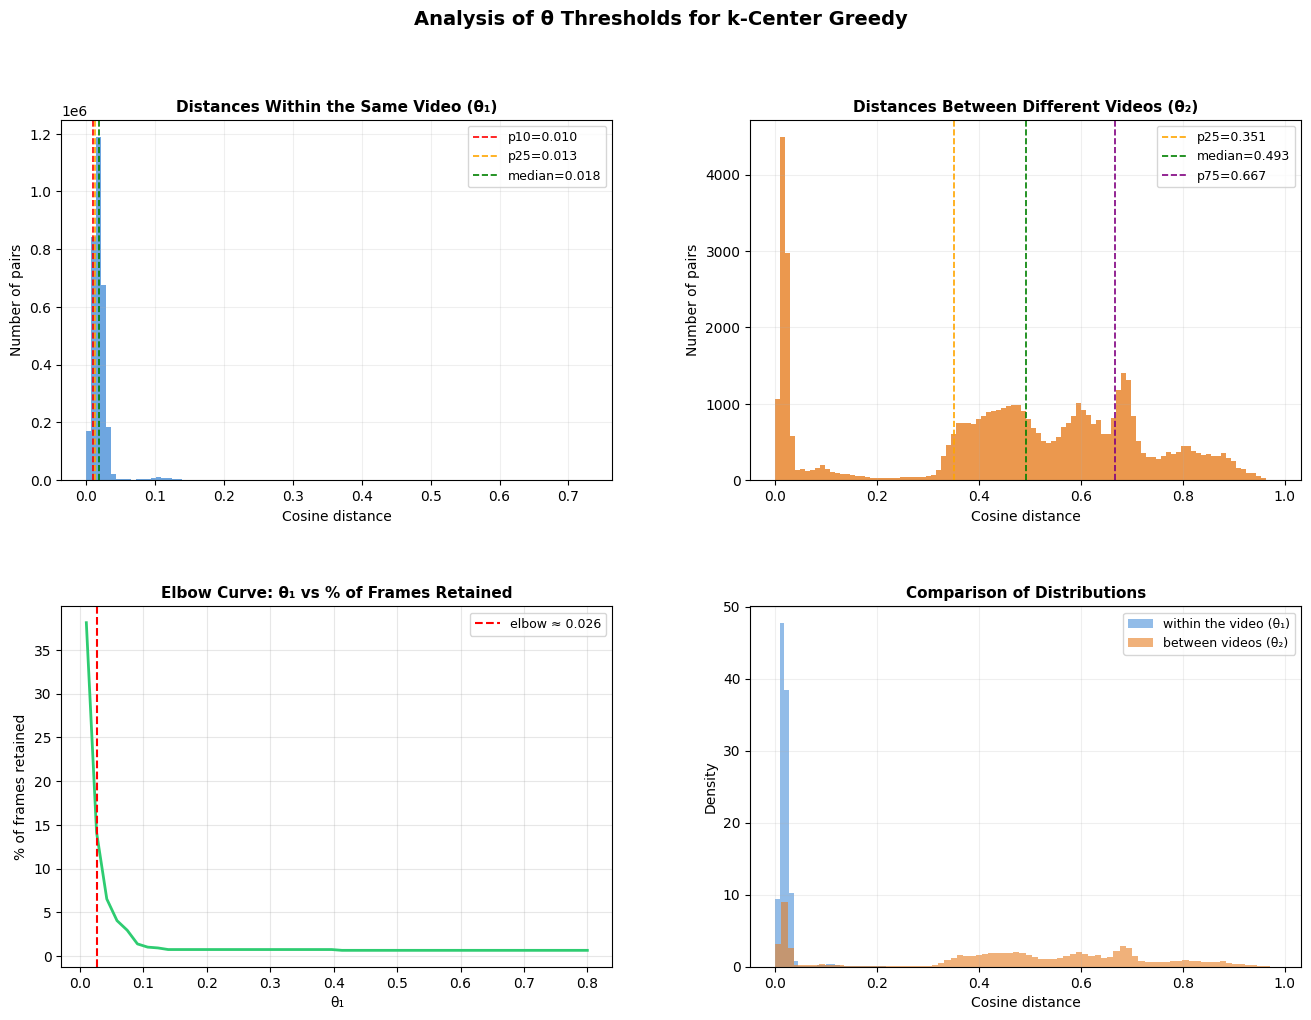


RECOMMENDATIONS FOR THETA
theta1 (video-level threshold):
  Conservative (p10):   0.0097  — removes ~10% of the most static pairs
  Elbow curve:          0.0261  — optimal balance of dataset size & diversity
  Moderate     (p25):   0.0133  — more aggressive frame removal

theta2 (dataset-level threshold):
  Conservative (p15):   0.0248  — removes redundant duplicate scenes
  Moderate     (p30):   0.3837  — more aggressive dataset pruning

Recommendation: start with theta1=0.026 and theta2=0.025
                after running Greedy selection, visually verify results on 2-3 videos


In [19]:
run_theta_analysis(embeddings_neg)